In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [3]:
train = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_test.csv")
test = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_train.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [4]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [6]:

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8336 - loss: 0.5676 - val_accuracy: 0.9460 - val_loss: 0.1847
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9632 - loss: 0.1260 - val_accuracy: 0.9590 - val_loss: 0.1453
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9751 - loss: 0.0788 - val_accuracy: 0.9750 - val_loss: 0.0962
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9827 - loss: 0.0595 - val_accuracy: 0.9710 - val_loss: 0.1025
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9874 - loss: 0.0400 - val_accuracy: 0.9720 - val_loss: 0.0906


In [7]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Loss: 0.1179
Test Accuracy: 96.57 %


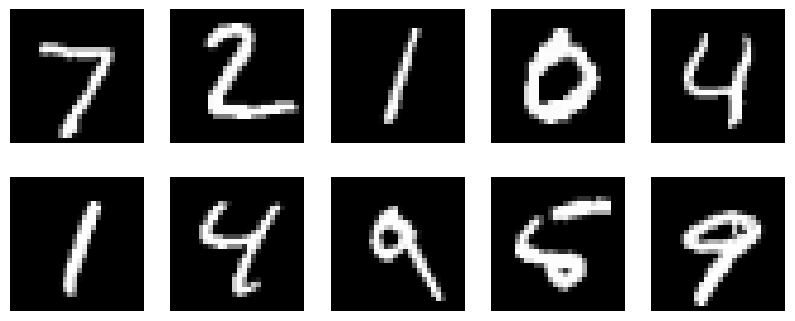

In [8]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()

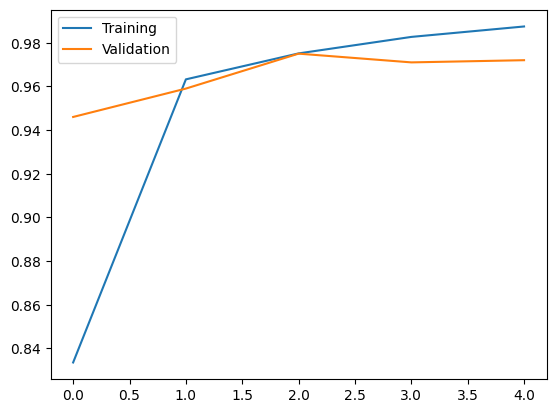

In [9]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.show()

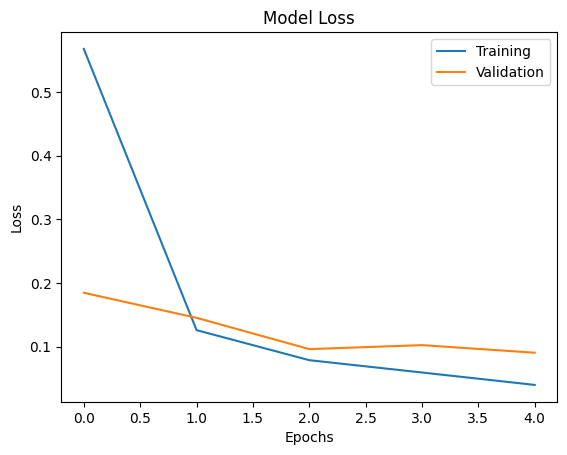

In [10]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()